In [ ]:
!pip install lightkurve
import numpy as np, lightkurve as lk, matplotlib.pyplot as plt
from scipy.optimize import curve_fit

for name in ["AI Phe", "RR Lyn", "V505 Per", "Algol"]:
    res = lk.search_lightcurve(name, mission="TESS", author="SPOC", exptime=120)
    print(name, len(res))

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 52.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 59.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 68.0 MB/s  0:00:00
  Created wheel for fbpca: filename=fbpca-1.0-py3-none-any.whl size=11429 sha256=f8f9426d4216ece449afe4915b7b1ae01a21777d00bc11f0fbb0b3c242b592ac
  Stored in directory: /root/.cache/pip/wheels/30/85/d4/289ba063a9ae0ba3189c6914e992722575868b2cb41100401b
  Created wheel for memoization: filename=memoization-0.4.0-py3-none-any.whl size=50537 sha256=5f68010bbe267aef4af72addf4ffcc0d49eb67a45fe2c778d968f94d8a0b0a6a
  Stored in directory: /root/.cache/pip/wheels/5c/ef/65/c51178502ccdadab909ffa9339a9a897019

/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


AI Phe 8
RR Lyn 3
V505 Per 3
Algol 3


<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Flux [$\\mathrm{e^{-}\\,s^{-1}}$]'>

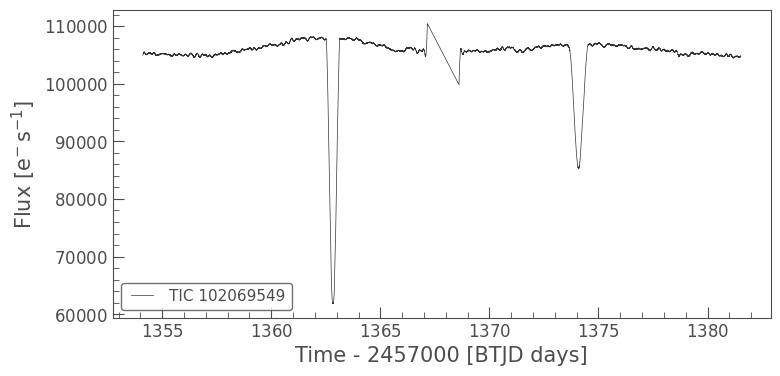

In [ ]:
res = lk.search_lightcurve("AI Phe", mission="TESS", author="SPOC", exptime=120)
lc = res[0].download()
lc.plot()

<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Normalized Flux'>

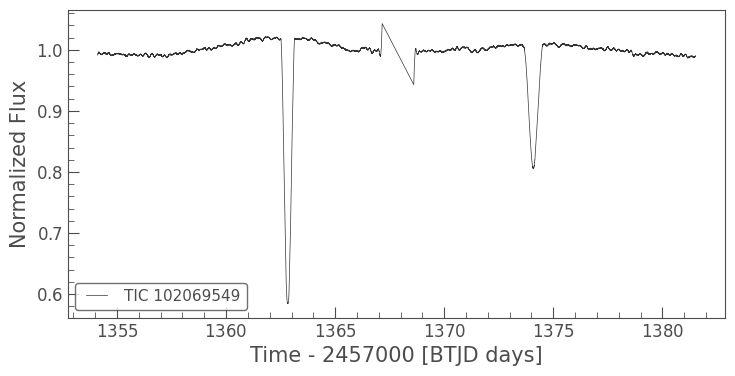

In [ ]:
lc = lc.remove_nans().normalize()
lc = lc.remove_outliers(sigma_upper=4, sigma_lower=float("inf"))
lc.plot()

2 1354.111847206799 1381.517615862553 18298


<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Normalized Flux'>

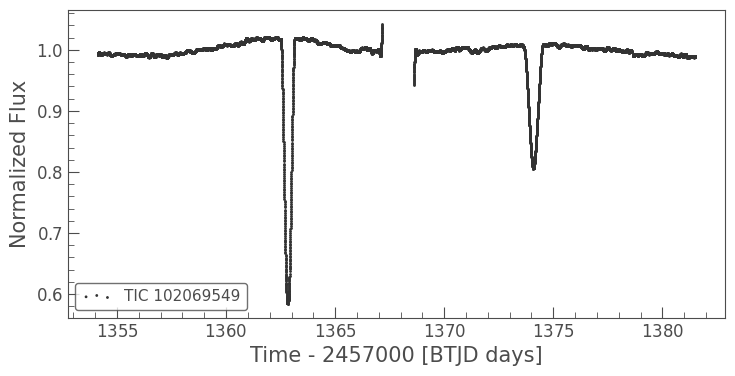

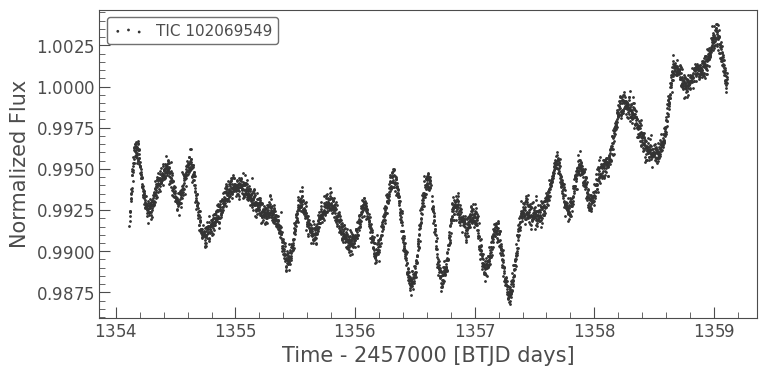

In [ ]:
print(lc.sector, lc.time.value.min(), lc.time.value.max(), len(lc))
lc.scatter()            # points instead of a line, to see gaps

# zoom into a 5-day window from the start
t = lc.time.value
w = lc[(t > t.min()) & (t < t.min() + 5)]
w.scatter()

In [ ]:
print(lc.flux.min(), lc.flux.max())

0.5842255353927612 1.043111801147461


0.614155650138855 1.072678804397583


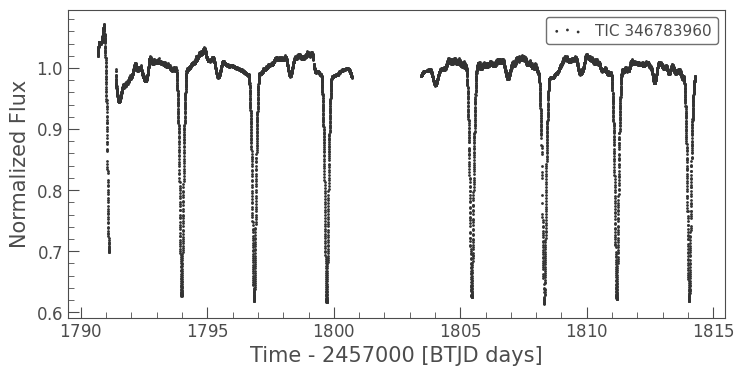

In [ ]:
res = lk.search_lightcurve("Algol", mission="TESS", author="SPOC", exptime=120)
lc = res[0].download()
lc = lc.remove_nans().normalize()
lc = lc.remove_outliers(sigma_upper=4, sigma_lower=float("inf"))
lc.scatter()
print(lc.flux.min(), lc.flux.max())

Period (d): 2.8656682834141707


<Axes: xlabel='Phase [JD]', ylabel='Normalized Flux'>

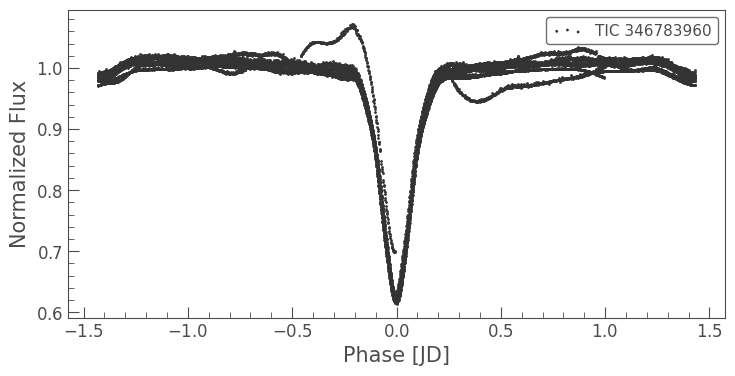

In [ ]:

pg = lc.to_periodogram("bls", period=np.linspace(0.5, 6, 20000),
                       duration=[0.2, 0.3, 0.4])
P  = pg.period_at_max_power.value
t0 = pg.transit_time_at_max_power
print("Period (d):", P)
lc.fold(period=P, epoch_time=t0).scatter()

[0.35877222 0.07006235 0.99568841] [0.00095927 0.00023133 0.00037387]


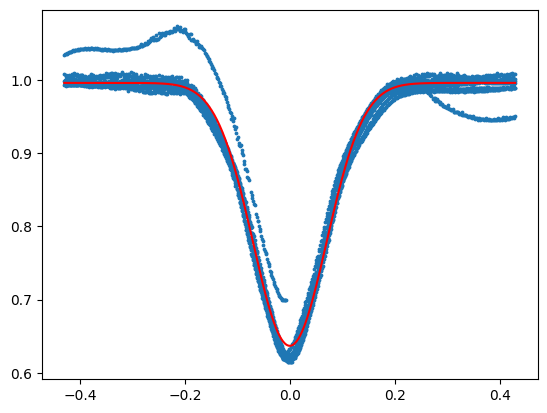

In [ ]:
f = lc.fold(period=P, epoch_time=t0)
x, y = f.time.value, f.flux.value
m = np.abs(x) < 0.15 * P

def dip(x, depth, width, base):
    return base - depth * np.exp(-0.5 * (x / width) ** 2)

popt, pcov = curve_fit(dip, x[m], y[m], p0=[0.5, 0.1, 1.0])
print(popt, np.sqrt(np.diag(pcov)))

plt.scatter(x[m], y[m], s=3)
xx = np.linspace(x[m].min(), x[m].max(), 500)
plt.plot(xx, dip(xx, *popt), "r"); plt.show()

In [ ]:
depth, width, base = popt
print("depth:", depth, "+/-", np.sqrt(pcov[0,0]))
print("width (sigma, days):", width)
print("FWHM (days):", 2.355 * width)

depth: 0.35877221679184934 +/- 0.0009592657933827108
width (sigma, days): 0.07006235336011389
FWHM (days): 0.1649968421630682


In [ ]:
print("deepest folded point:", 1 - y[m].min())
print("median near centre:", 1 - np.median(y[np.abs(x) < 0.02]))

deepest folded point: 0.38584435
median near centre: 0.37220663
